# mem pipeline：每个环节的一个示例
**配套文档：** [pipeline.ipynb](pipeline.ipynb)（各环节的想法、要求和缺口，意见写在那里）· 场景 SceneFun3D 421069，视频 42444490 · 2026-11-11

这份 notebook 按 [pipeline.ipynb](pipeline.ipynb) 的环节编号，用同一个真实场景给每个环节一个看得见的例子，方便理解每一步在做什么。记忆采用第四轮讨论定下的形式（L2）：**每个关键帧的图，加上部件 token 和一层很薄的显式索引；接触点等几何量不存，读取时现算；检索先用 affordance token 和传统语义找关键帧，再交给视觉语言模型。**

**读图之前请注意三点**

- **这是示例，不是结果。** 只有一个场景、一段视频、18 个可回答的任务，数字只用来说明每一步的行为和误差从哪里来。
- **affordance map 和部件运动仍然是 ORACLE**（取自 SceneFun3D 标注）。其余都只用输入算出：RGB、单目深度（按设备 LiDAR 校正尺度）、设备位姿。
- **没有训练任何东西，也没有用 GPU。** 两种特征和视觉语言模型都是现成的公开模型，在 CPU 上运行。

| 标记 | 含义 |
| --- | --- |
| 真实 | 只用输入算出 |
| ORACLE | 取自标注，以后换成模型预测 |
| 现成模型 | 公开模型，未训练、未调整 |
| 示意 | 这段视频里做不了，只画出打算怎么做 |
| 真值 | 激光扫描、扫描渲染的深度、配准位姿、部件编号：只用于打分和画图，从不作为输入 |

<sub>重新运行：先按 [演示 notebook](../../report/2026-11-10_mem_pipeline_demo.ipynb) 开头的说明准备场景数据和 SMPL-X；服务器上用 `python scripts/remote/fetch_models.py` 取两个模型；然后 Run All（CPU，约半小时，其中视觉语言模型约一刻钟，答案会缓存在 `runs/mem_l2/`）。</sub>

In [1]:
import contextlib
import io
import json
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Video, display
from matplotlib_inline.backend_inline import set_matplotlib_formats

os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")  # no model-loading chatter in the outputs
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "affordance3d").is_dir())
_saved_fd, _null = os.dup(1), os.open(os.devnull, os.O_WRONLY)
os.dup2(_null, 1)  # silence Open3D's import banner (printed from C++)
try:
    with contextlib.redirect_stdout(io.StringIO()):
        import open3d  # noqa: F401
finally:
    os.dup2(_saved_fd, 1)
sys.path.insert(0, str(ROOT))
from affordance3d.features import DinoV2Extractor, fit_pca_coloring
from affordance3d.mem import pipeline as P
from affordance3d.mem import search as S
from affordance3d.mem import tokens as T
from affordance3d.mem.body import load_smplx
from affordance3d.mem.depth_models import depth_errors
from affordance3d.mem.encoders import VLM_REVISION, ImageTextEncoder, VisionLanguageModel
from report import mem_steps_helpers as H
from report.mem_demo_helpers import (humanoid_figure, inputs_figure, labels_figure, pick_keyframes, render_approach_video,
                                     scaled_mono_depths, scan_view, scoreboard, shots_for, shots_table)

from transformers.utils import logging as transformers_logging

transformers_logging.disable_progress_bar()
set_matplotlib_formats("jpeg")
plt.rcParams.update({"figure.dpi": 90})
pd.set_option("display.max_colwidth", 90)
torch.set_num_threads(48)  # shared server: leave most cores to others
DATA, VISIT, VIDEO = ROOT / "data" / "scenefun3d", "421069", "42444490"
ASSETS, RUNS = ROOT / "report" / "assets", ROOT / "runs" / "mem_l2"
MONO_ID = "depth-anything/Depth-Anything-V2-Metric-Indoor-Large-hf"
MONO_CACHE = ROOT / "runs" / "mem_s1" / "mono" / "DA-V2_L"
N_KEYFRAMES, VISUAL_INPUT_HW, TOP_KEYFRAMES = 40, (952, 714), 3
EXAMPLE_TASKS = ("Increase the toaster's intensity", "Open the top oven door",
                 "Open the trash can located in the kitchen near the sink", "Turn on the floor lamp next to the couch")

## 总览：写入一次，读取多次

上半部分是**写入**：一段视频只做一次，得到记忆。下半部分是**读取**：每来一个查询做一次。方框里的数字是 [pipeline.ipynb](pipeline.ipynb) 的环节编号，颜色表示这个环节现在的状态。

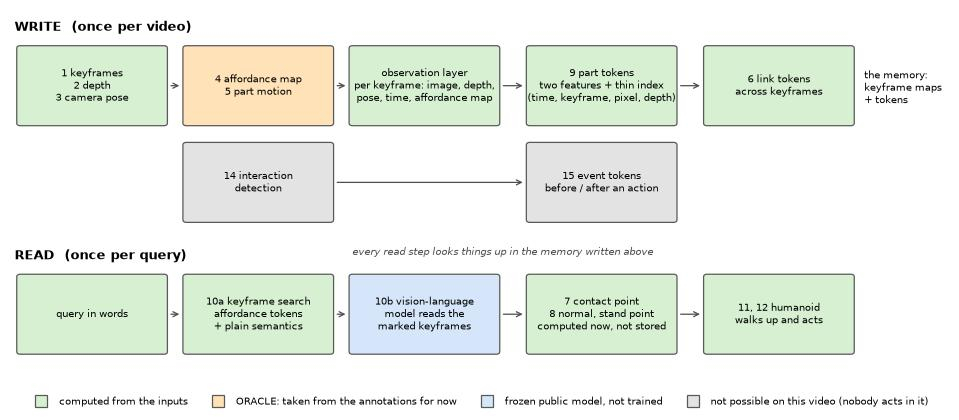

In [2]:
H.overview_figure()
plt.show()

## 环节 1 · 关键帧选取
> **这一步做什么：** 从 1025 帧视频里按时间均匀取 40 帧。之后的记忆只来自这 40 帧。
> **状态：** 真实。

**怎么看图：** 左上是相机走过的路线（俯视），彩色点是关键帧，颜色表示时间。右上是关键帧取多少会影响能看到多少个部件（"看到"指至少占 10 个像素，这个统计用了标注）。下面一排是其中 8 个关键帧。

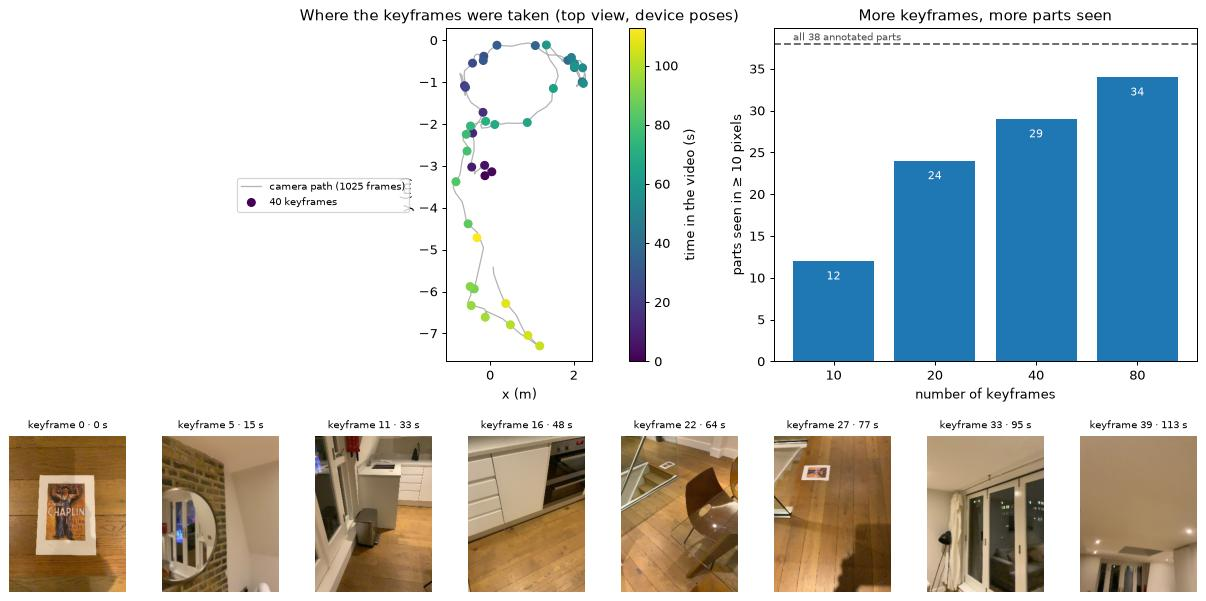

In [3]:
scene = P.load_scene(DATA, VISIT, VIDEO)
keyframes = pick_keyframes(scene, N_KEYFRAMES)
mono = scaled_mono_depths(scene, keyframes, MONO_ID, MONO_CACHE)
frames = [P.input_frame(scene, t, d) for t, d in zip(keyframes, mono)]  # what the memory may use
gt = P.gt_frames(scene, keyframes)  # ground-truth cameras: labels and scoring only
seconds = H.seconds_of(scene, keyframes)
seen_by_count = {n: H.parts_seen(scene, n) for n in (10, 20, 40, 80)}

H.keyframes_figure(scene, keyframes, frames, seen_by_count)
plt.show()

## 环节 2 · 深度
> **这一步做什么：** 给每个关键帧一张深度图。用单目深度模型（Depth Anything V2）估计，再按这一帧的设备 LiDAR 校正尺度。
> **状态：** 真实。最右一格是真值，只用于打分。

**怎么看图：** 第 2、3 格是两种可用的输入深度。LiDAR 更准但分辨率低、有空洞；单目深度是稠密的，小部件处误差更大。

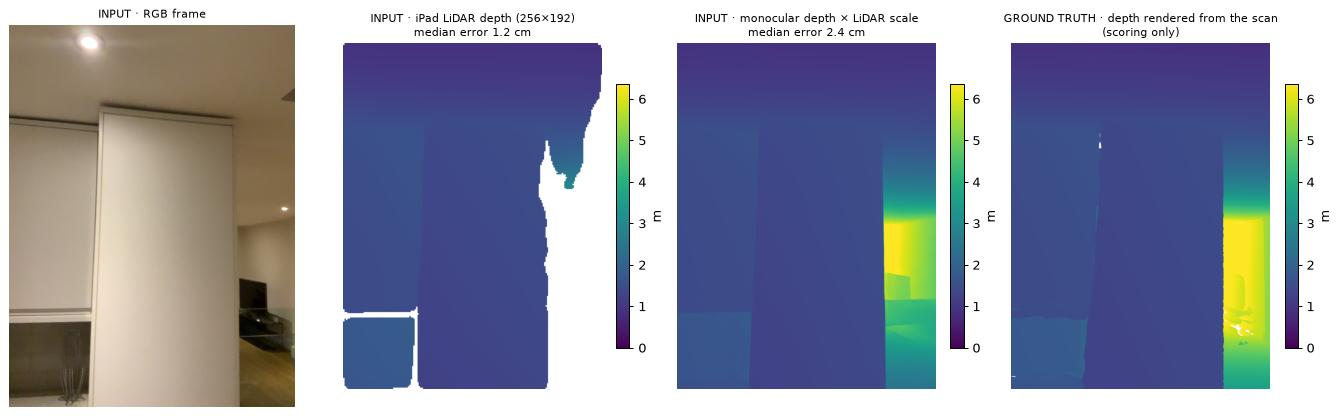

monocular depth × LiDAR scale, median error over the 40 keyframes: 4.7 cm


In [4]:
inputs_figure(scene, keyframes[18], mono[18], gt[18])
plt.show()
whole = [100 * depth_errors(m, g.depth_m)["median_abs_m"] for m, g in zip(mono, gt)]
print(f"monocular depth × LiDAR scale, median error over the {len(keyframes)} keyframes: {np.median(whole):.1f} cm")

## 环节 3 · 相机位姿
> **这一步做什么：** 每个关键帧的相机位置和朝向，直接用设备（ARKit）给出的。
> **状态：** 真实。灰色的真值位姿只用于对照。

**怎么看图：** 左边红线越长，这一帧的位姿误差越大。位姿误差会让"同一个部件在两帧里算出的位置"对不上，环节 6 会看到它的影响。

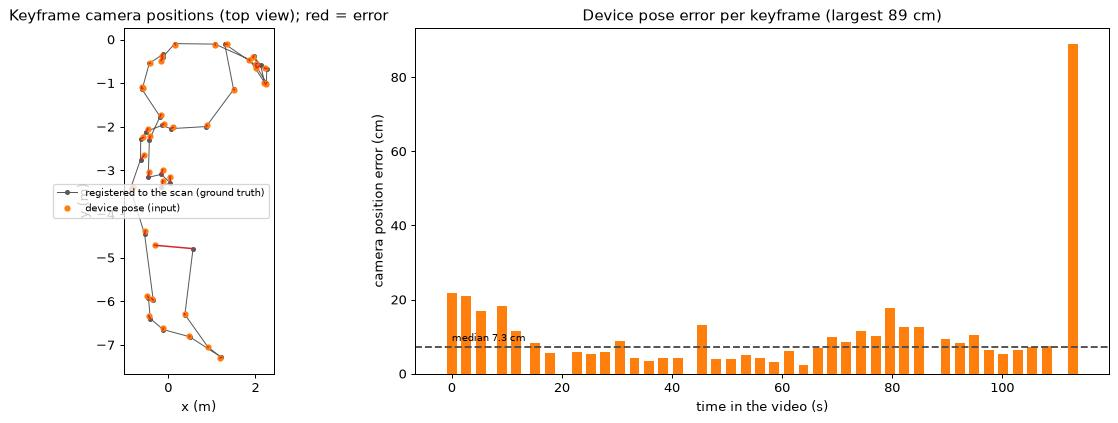

In [5]:
H.pose_figure(scene, keyframes, frames, gt)
plt.show()

## 环节 4 · affordance map
> **这一步做什么：** 给每个关键帧一张图，标出"哪些像素可以操作、用哪种动作"。连在一起的同一种动作的像素算一个**区域**（图里的白框）。
> **状态：** ORACLE。现在是把扫描上的标注投影到关键帧，并且**去掉了部件编号**：记忆只知道动作类型，不知道哪个区域是哪个部件。

**怎么看图：** 颜色是 9 类动作。白框和编号是从图上直接找出的区域，之后每个区域变成一个 token。投影出来的标注是稀疏的点，这里做了一步填充，让它像模型预测的稠密图。

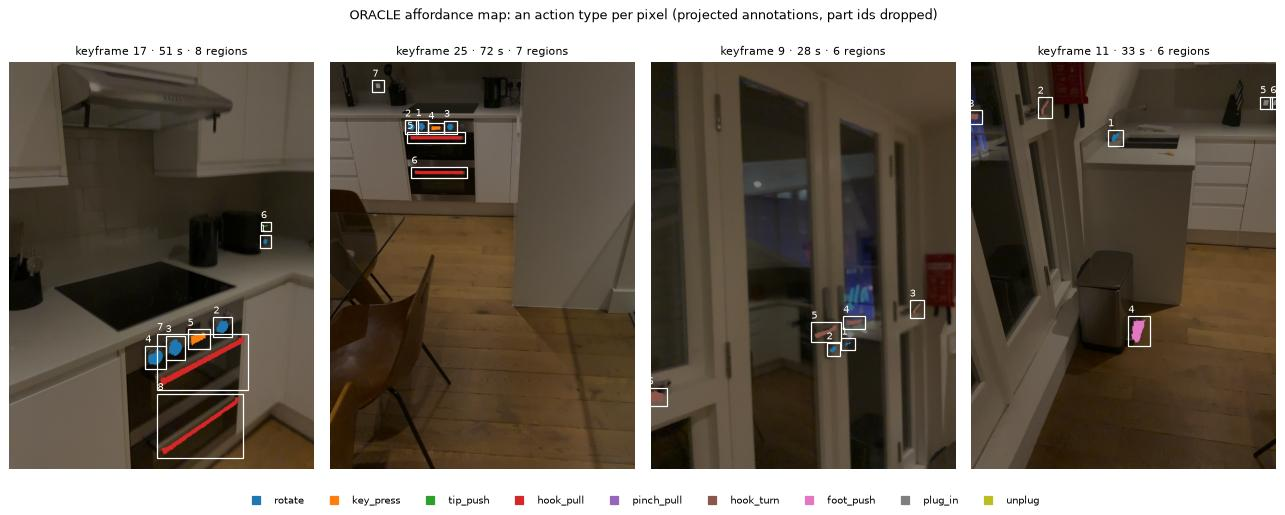

62 regions in 22 of 40 keyframes


In [6]:
part_labels = P.label_maps(scene, gt)  # ORACLE with part ids: kept aside, for scoring only
part_actions = [T.ACTIONS.index(element.label) for element in scene.elements]
action_maps = [T.action_map(labels, part_actions) for labels in part_labels]  # the affordance map: no part ids
regions = [T.find_regions(actions, frame.depth_m, k)[1] for k, (actions, frame) in enumerate(zip(action_maps, frames))]

H.affordance_figure(frames, action_maps, regions, seconds)
plt.show()
print(f"{sum(len(r) for r in regions)} regions in {sum(bool(r) for r in regions)} of {len(frames)} keyframes")

### 标注和画面对得上吗（做示例时发现的问题）
> **检查什么：** 标注是用真值相机位姿投影到关键帧上的。如果投影出来的位置和画面里的真实部件错开，后面按这个位置取特征、取深度、画框都会偏。
> **状态：** 真值的问题，不是方法的问题；但它影响所有用 ORACLE 标注的环节，也影响以后制作训练标签。

**怎么看图：** 第一张图左边两格是相机转得最快的一个关键帧，右边两格是转得最慢的一个（都只放大有标注的部分）。黄色是投影出来的标注。相机转得快时，黄色明显偏离真实的旋钮和把手；转得慢时基本重合。相机转速由设备位姿算出，是输入，不需要真值。

第二张图检查这种错位是否已经反映在接触点误差上：每个点是 v1 的一个条目，横轴是它的证据帧里相机的转速，纵轴是接触点误差，图题是两者的秩相关系数。只有二十几个条目，这张图只能看趋势，不足以下结论。

原因还没有查清：可能是画面的曝光时刻和位姿的时刻不一致，也可能是画面模糊时真值位姿本身不准。

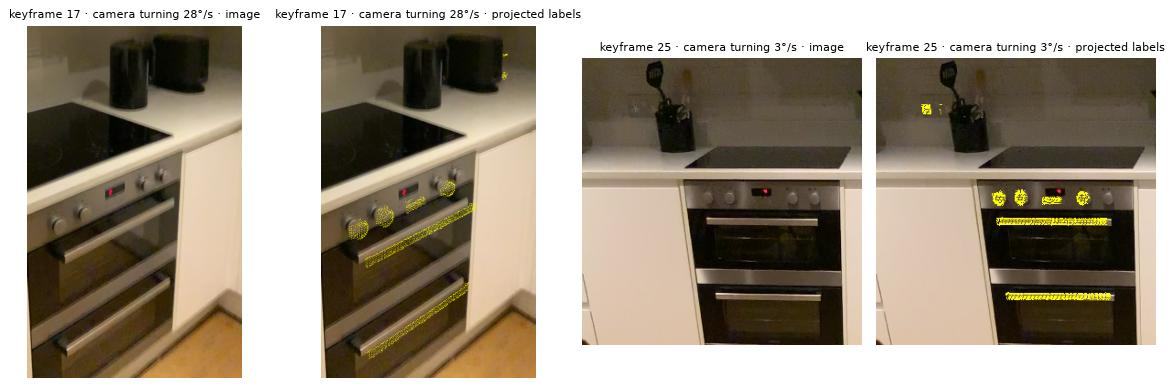

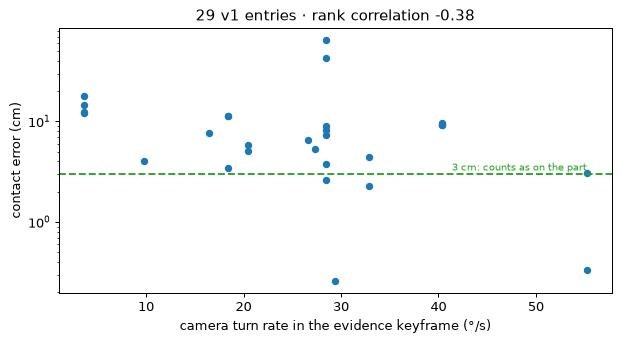

camera turn rate of the 22 keyframes with regions: median 24°/s, from 3 to 55°/s


In [7]:
rates = H.turn_rates(scene, keyframes)  # from device poses: an input
labelled = [k for k in range(len(frames)) if len(regions[k]) >= 4]
fastest, slowest = max(labelled, key=lambda k: rates[k]), min(labelled, key=lambda k: rates[k])
H.alignment_figure(frames, part_labels, rates, [fastest, slowest])
plt.show()
explicit = P.build_memory(scene, keyframes, frames, part_labels)  # v1: explicit entries, written with part ids
with_regions = [k for k in range(len(frames)) if regions[k]]
turn_figure, turn_correlation = H.turn_rate_figure(scene, explicit, dict(zip(keyframes, rates)))
plt.show()
print(f"camera turn rate of the {len(with_regions)} keyframes with regions: median {np.median(rates[with_regions]):.0f}°/s, "
      f"from {rates[with_regions].min():.0f} to {rates[with_regions].max():.0f}°/s")

## 环节 5 · 部件运动
> **这一步做什么：** 每个部件怎么动：转动还是平移，绕哪根轴或朝哪个方向。
> **状态：** ORACLE，直接取自标注。它现在只用于人形画面里的黄色箭头，还没有进入记忆的特征。

**怎么看图：** 白色箭头是标注的运动轴，投影到关键帧上。

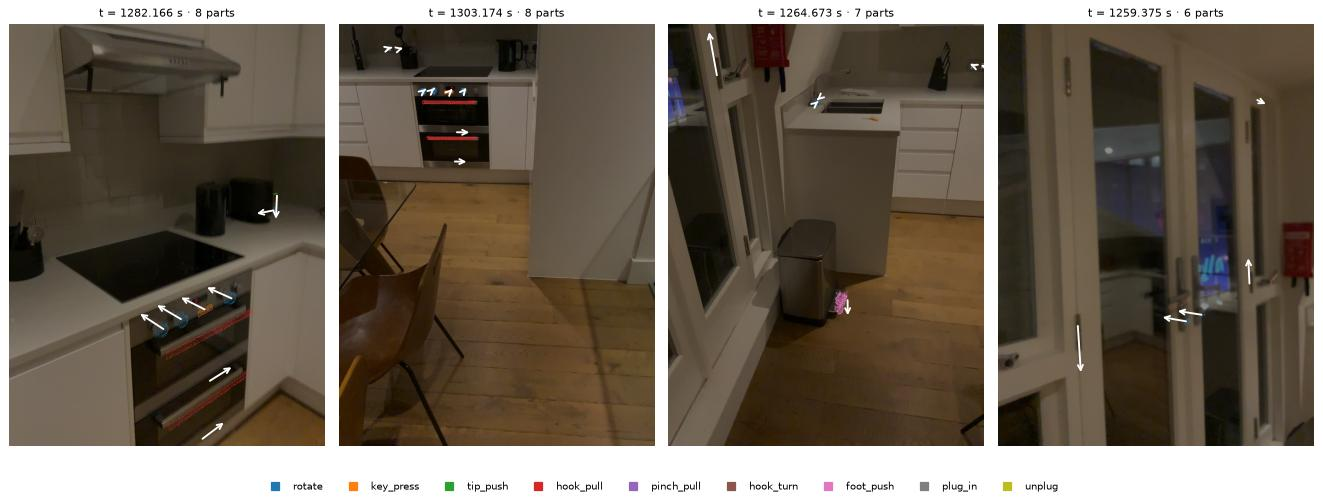

In [8]:
labels_figure(scene, gt, part_labels, keyframes)
plt.show()

---
# 写入记忆

## 环节 9 · 部件 token：两种特征，加一层薄索引
> **这一步做什么：** 把环节 4 的每个区域写成一个 **token**。
> - **视觉特征**（自监督模型 DINOv2）：区域覆盖的图像小块的特征取平均，用来认出"同一个部件"。
> - **语义特征**（图文模型 SigLIP 2）：把区域连同周围一圈裁出来编码，用来和文字查询比较。
> - **薄索引**（显式）：时间、哪个关键帧、区域中心的像素、到相机的深度、动作类型。
>
> **状态：** 真实（现成模型，未训练）。接触点、法向、站立点**不在这里存**。

**怎么看图：** 左：一个关键帧和它的区域。中：整帧的视觉特征（颜色相近表示特征相近）。右：图文模型实际看到的裁剪图，黄框是区域本身。下面的表是这几个 token 存下来的全部内容。

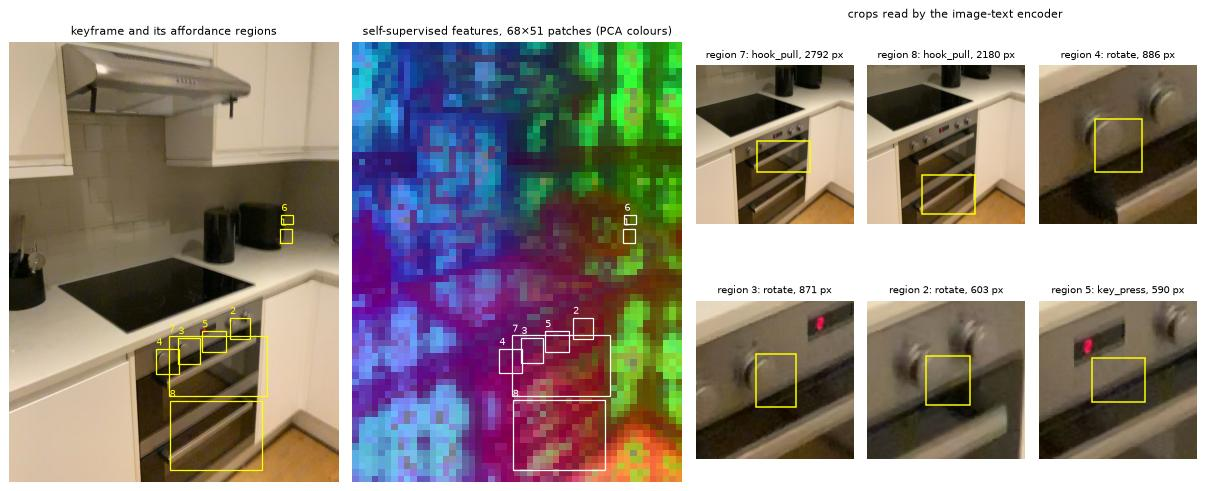

written in 89 s on the CPU: 62 tokens from 40 keyframes


,part,time,keyframe,action type,"pixel (u, v)",depth,pixels,visual feature,semantic feature
token,,,,,,,,,
27,19,50.7 s,17,rotate,"(604, 422)",2.27 m,92,384 numbers,768 numbers
28,14,50.7 s,17,rotate,"(503, 624)",1.42 m,603,384 numbers,768 numbers
29,15,50.7 s,17,rotate,"(392, 674)",1.24 m,871,384 numbers,768 numbers
30,20,50.7 s,17,rotate,"(346, 697)",1.18 m,886,384 numbers,768 numbers
31,16,50.7 s,17,key_press,"(444, 650)",1.33 m,590,384 numbers,768 numbers
32,21,50.7 s,17,tip_push,"(606, 386)",2.45 m,29,384 numbers,768 numbers


In [9]:
start = time.time()
dino = DinoV2Extractor(input_hw=VISUAL_INPUT_HW)
grids = [dino(frame.rgb).grid for frame in frames]
encoder = ImageTextEncoder()
keyframe_vectors = encoder.images([frame.rgb for frame in frames])  # whole keyframes, for plain semantic search
memory = T.write_memory(keyframes, frames, action_maps, grids, encoder.images, scene.up,
                        start_s=float(scene.vid.rgb_times[0]))
write_seconds = time.time() - start

colouring = fit_pca_coloring(np.concatenate([grid.reshape(-1, grid.shape[-1])[::7] for grid in grids]))
example_k = max(range(len(frames)), key=lambda k: len(regions[k]))
in_example = [i for i, token in enumerate(memory.tokens) if token.region.keyframe == example_k]
H.features_figure(frames[example_k], grids[example_k], colouring, [memory.tokens[i].region for i in in_example])
plt.show()
print(f"written in {write_seconds:.0f} s on the CPU: {len(memory.tokens)} tokens from {len(frames)} keyframes")
H.token_table(memory, in_example[:6])

## 环节 6 · 跨帧关联
> **这一步做什么：** 判断不同关键帧里的 token 是不是同一个部件。规则很简单：动作类型相同、算出的位置相距不超过 30 cm、视觉特征足够像，就连到最近的那个部件上；否则新建一个部件。同一个部件的 token 全部保留，不取平均。
> **状态：** 真实。没有用部件编号；编号只在这里用来打分。

**怎么看图：** 第一张图每行是一个部件的全部 token，按时间排列；绿框表示连对了，红框表示把别的部件连了进来。第二张图解释为什么难：左边，同一个部件两次看到时算出的位置并不重合（深度和位姿都有误差）；右边，挨得近的同类部件（比如相邻的旋钮）特征几乎一样，所以只能靠位置区分。

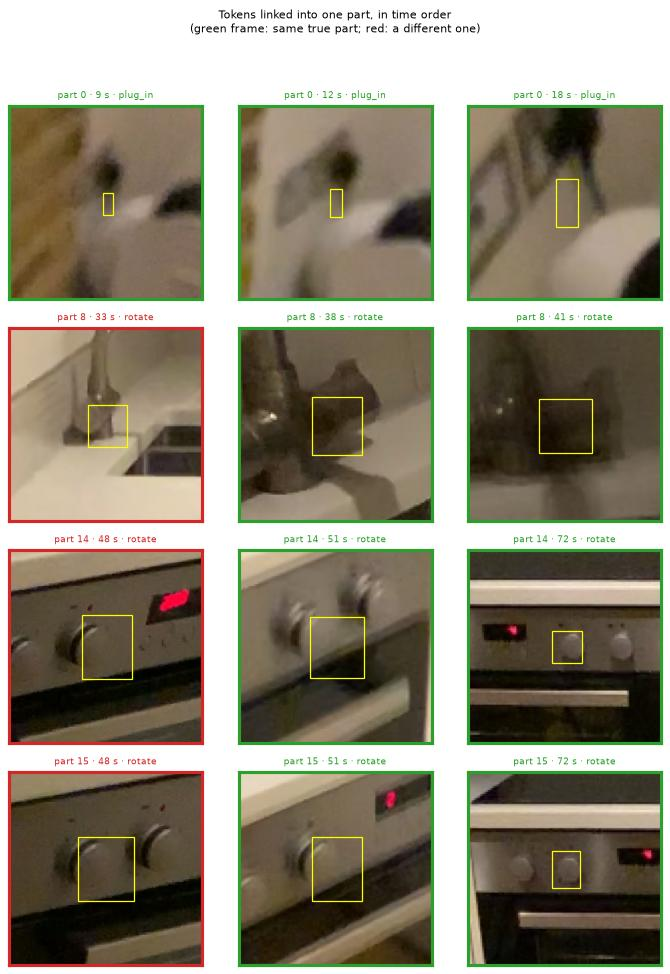

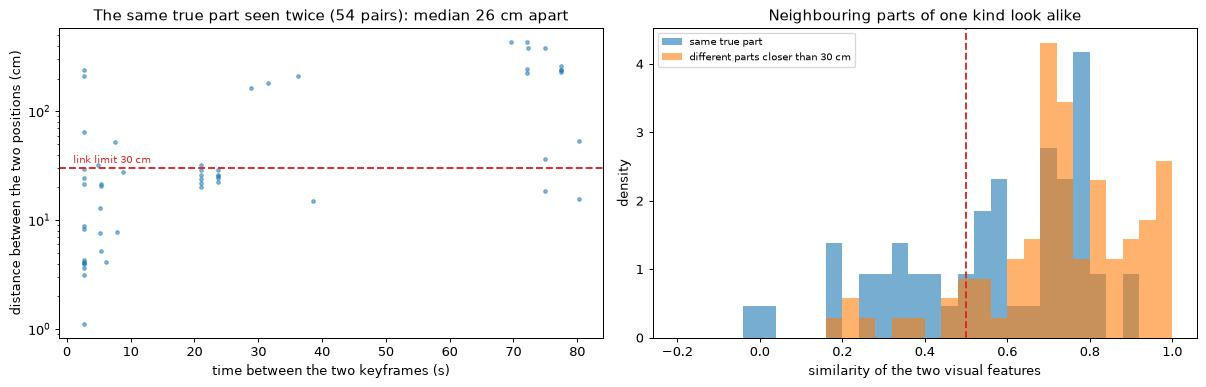

,tokens,true parts with a token,parts in the memory,tokens whose part is not mixed,a true part stays in one piece (mean share),parts linked exactly right
0,62,28,39,94%,83%,14 of 28


In [10]:
truth = H.truth_parts(memory, part_labels, len(scene.elements))  # ground truth, for scoring only
H.linking_figure(memory, frames, truth)
plt.show()
H.pair_figure(memory, frames, truth)
plt.show()
H.linking_scores(memory, truth)

## 记忆里到底存了什么、有多大
> **状态：** 实测的字节数。

L2 记忆 = 每个关键帧的图（原图、深度、affordance 图、位姿）+ 部件 token。下表把它和 v1 的显式条目、和整个房间的激光扫描放在一起比较。

In [11]:
H.storage_table(scene, DATA / VISIT / f"{VISIT}_laser_scan.ply", keyframes, frames, action_maps, memory, explicit)

size
group          what                                                            
L2 memory      keyframe images (as in the dataset)                     13.64 MB
               depth maps (16-bit PNG, millimetres)                    12.72 MB
               affordance maps (PNG)                                    0.10 MB
               camera poses, intrinsics                                  8.1 KB
               part tokens: features of 62 tokens (16-bit)              0.14 MB
               part tokens: thin index                                   5.3 KB
for comparison v1 explicit entries (29 parts)                           15.6 KB
               laser scan of the room (ground truth, never an input)  133.21 MB

---
# 读取记忆

## 环节 10a · 先找关键帧：affordance token 加传统语义
> **这一步做什么：** 给一句任务，先找出最可能包含目标部件的几个关键帧。两种线索相加：
> - **传统语义：** 任务文字和**整个关键帧**的图文相似度。没有 affordance 的记忆只能这样找。
> - **affordance token：** 任务文字和**每个可操作区域的裁剪图**的图文相似度，一个关键帧取它最好的区域。
>
> **状态：** 真实（现成模型）。对错用标注判断：关键帧里确实拍到了任务指的部件就算对。

**怎么看图：** 每行一个任务。左四张是只用传统语义排出的前四个关键帧，右四张是加上 affordance token 之后的前四个；绿框表示这个关键帧里有正确的部件，黄框是其中得分最高的区域。下面的表是全部可回答任务的统计。

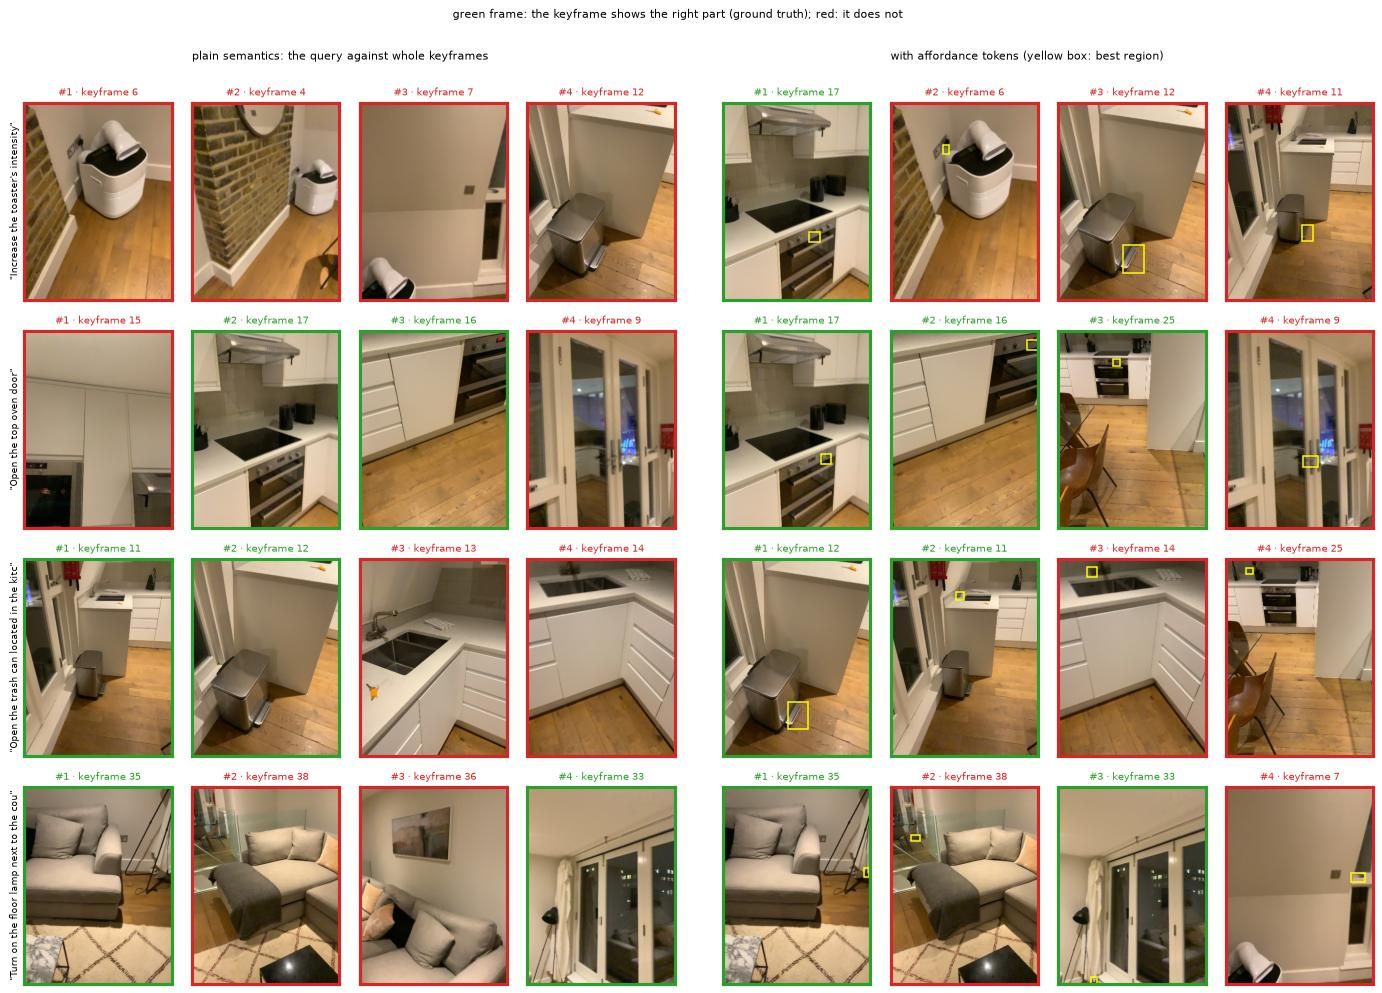

18 of 24 tasks name a part that some keyframe shows; search takes 0.2 ms per query
action type guessed from the task words alone is right for 7 of 18 tasks


,a right keyframe in the top 1,a right keyframe in the top 3,a right keyframe in the top 5
plain semantics (whole keyframes),67%,83%,83%
affordance tokens only,33%,72%,89%
both together (used below),83%,100%,100%
both + action type guessed from the words,83%,100%,100%


In [12]:
tasks = [task for task in H.tasks_of(scene, part_labels) if task.keyframes]  # tasks whose part is in some keyframe
query_vectors = encoder.texts([task.text for task in tasks])
token_vectors = np.array([token.semantic for token in memory.tokens])
token_keyframe = [token.region.keyframe for token in memory.tokens]
token_action = [token.region.action for token in memory.tokens]
start = time.time()
scores = [S.score_keyframes(q, keyframe_vectors, token_vectors, token_keyframe, token_action) for q in query_vectors]
search_ms = 1000 * (time.time() - start) / len(tasks)

examples = [next(i for i, task in enumerate(tasks) if task.text == text) for text in EXAMPLE_TASKS]
H.search_figure(frames, memory, [(tasks[i], scores[i]) for i in examples])
plt.show()
action_vectors = encoder.texts([S.ACTION_PROMPTS[name] for name in T.ACTIONS])
affinities = [S.action_affinity(q, action_vectors) for q in query_vectors]
with_action = [S.score_keyframes(q, keyframe_vectors, token_vectors, token_keyframe, token_action, a)
               for q, a in zip(query_vectors, affinities)]
hits = {"plain semantics (whole keyframes)": [S.first_hit(s.ranking("semantic"), t.keyframes) for s, t in zip(scores, tasks)],
        "affordance tokens only": [S.first_hit(s.ranking("afford"), t.keyframes) for s, t in zip(scores, tasks)],
        "both together (used below)": [S.first_hit(s.ranking(), t.keyframes) for s, t in zip(scores, tasks)],
        "both + action type guessed from the words": [S.first_hit(s.ranking(), t.keyframes) for s, t in zip(with_action, tasks)]}
guessed = [int(np.argmax(a)) in {part_actions[p] for p in task.parts} for a, task in zip(affinities, tasks)]
print(f"{len(tasks)} of {len(scene.tasks)} tasks name a part that some keyframe shows; search takes {search_ms:.1f} ms per query")
print(f"action type guessed from the task words alone is right for {sum(guessed)} of {len(tasks)} tasks")
H.search_table(hits)

**关于动作类型：** affordance map 上最有特点的信息是动作类型。这里试了一种最简单的用法：用文字编码器从任务句子里猜动作类型，再给同类型的区域加分。上面打印的那一行是它猜对的比例，表的最后一行是加上它之后的排序结果。猜错的原因很直接："打开"可以是拉、转或者踩，光看文字分不出来。所以下面的流程**先不用文字猜的动作类型排序**，把"这个区域该怎么操作"留给视觉语言模型结合画面判断。动作类型怎么用，是环节 10 留给你的一个待定点。

## 环节 10b · 再交给视觉语言模型
> **这一步做什么：** 把排在最前面的 3 个关键帧交给视觉语言模型，图上每个可操作区域都画了框和编号，问它"要完成这个任务应该操作几号"。它选出的编号对应一个 token。
> **状态：** 现成模型（Qwen3-VL-4B，CPU，未训练）。对错用标注判断。

**怎么看图：** 每个例子是模型实际看到的三张图，绿色粗框是它选的编号。下面的表列出每个任务的结果。

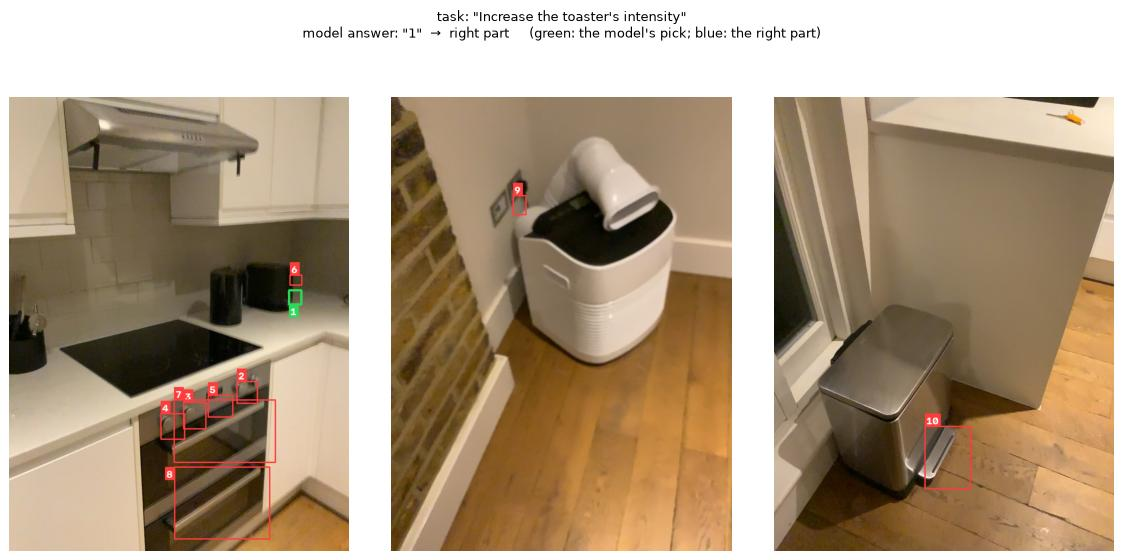

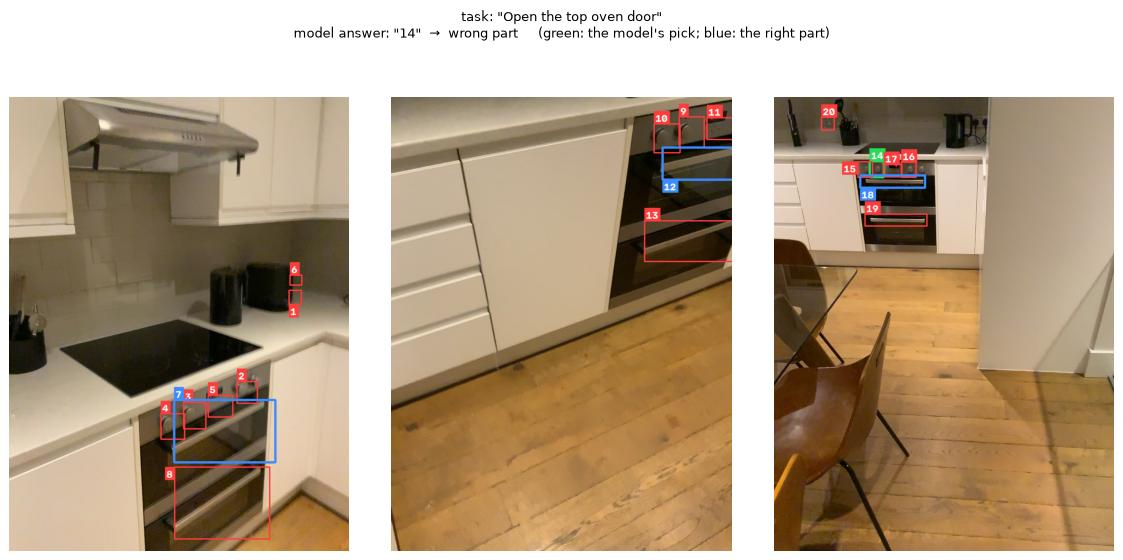

right part chosen: 10 of 18 tasks (18 had a right keyframe among the 3); median 60 s per task on the CPU


,task,a right keyframe among the 3,marks shown,model answer,right part chosen,seconds
0,Increase the toaster's intensity,True,10,1,True,59.8
1,Lock the left balcony door located in the kitchen,True,16,8,False,53.3
2,Lock the right balcony door located in the kitchen,True,16,8,False,66.0
3,Open the bottom oven door,True,20,19,True,49.9
4,Open the glass door next to the black floor lamp,True,11,2,True,59.9
5,Open the left balcony door located in the kitchen,True,14,8,False,76.4
6,Open the right balcony door located in the kitchen,True,14,8,False,142.3
7,Open the small window located near to the portable air conditioner,True,5,2,True,56.5
8,Open the top oven door,True,20,14,False,59.9
9,Open the trash can located in the kitchen near the sink,True,9,5,True,55.7


In [13]:
reader = H.CachedReader(RUNS / "vlm_answers.json", VisionLanguageModel)
rows, chosen_token = [], {}
for index, (task, score) in enumerate(zip(tasks, scores)):
    top = [int(k) for k in score.ranking()[:TOP_KEYFRAMES]]
    images, mark_tokens = H.marked_keyframes(frames, memory, top)
    prompt = S.mark_prompt(task.text, len(mark_tokens))
    reply = reader.ask(H.reading_key(VLM_REVISION, prompt, top, [memory.tokens[t].region.box for t in mark_tokens]), images, prompt)
    mark = S.parse_mark(reply["answer"], len(mark_tokens))
    token = mark_tokens[mark - 1] if mark else None
    chosen_token[index] = (top, mark, token, [n + 1 for n, t in enumerate(mark_tokens) if int(truth[t]) in task.parts])
    rows.append({"task": task.text, "a right keyframe among the 3": bool(task.keyframes & set(top)), "marks shown": len(mark_tokens),
                 "model answer": reply["answer"], "right part chosen": token is not None and int(truth[token]) in task.parts,
                 "seconds": reply["seconds"]})
readings = pd.DataFrame(rows)

for index in examples[:2]:
    top, mark, token, right = chosen_token[index]
    images, _ = H.marked_keyframes(frames, memory, top, chosen=mark, right=right)
    verdict = "right part" if rows[index]["right part chosen"] else "wrong part" if token is not None else "no valid number"
    H.reading_figure(images, tasks[index].text, rows[index]["model answer"], verdict)
    plt.show()
print(f"right part chosen: {int(readings['right part chosen'].sum())} of {len(readings)} tasks "
      f"({int(readings['a right keyframe among the 3'].sum())} had a right keyframe among the 3); "
      f"median {readings['seconds'].median():.0f} s per task on the CPU")
readings

## 环节 7、8 · 读取时现算：接触点、法向、站立点
> **这一步做什么：** 模型选出 token 之后，回到这个 token 的**证据帧**，用那一帧的深度现算三样东西：
> - **接触点**（红点）：区域中心的像素，加上区域深度的中位数。
> - **法向**（青色箭头）：接触点周围一小块表面的朝向。
> - **站立点**（圆环）：沿法向退半米落到地面；是否被挡，只看证据帧和它前后各 3 个关键帧里观察到的点。
>
> **状态：** 真实。这些量不在记忆里，每次查询时计算。

**怎么看图：** 上排是证据帧整幅图，下排是放大。标题里的"contact … cm"是接触点到它所标区域对应的真实部件的距离（真值，只用于打分）。如果上一步选错了部件，这里算出的就是那个错部件的几何量，标题里会写明。

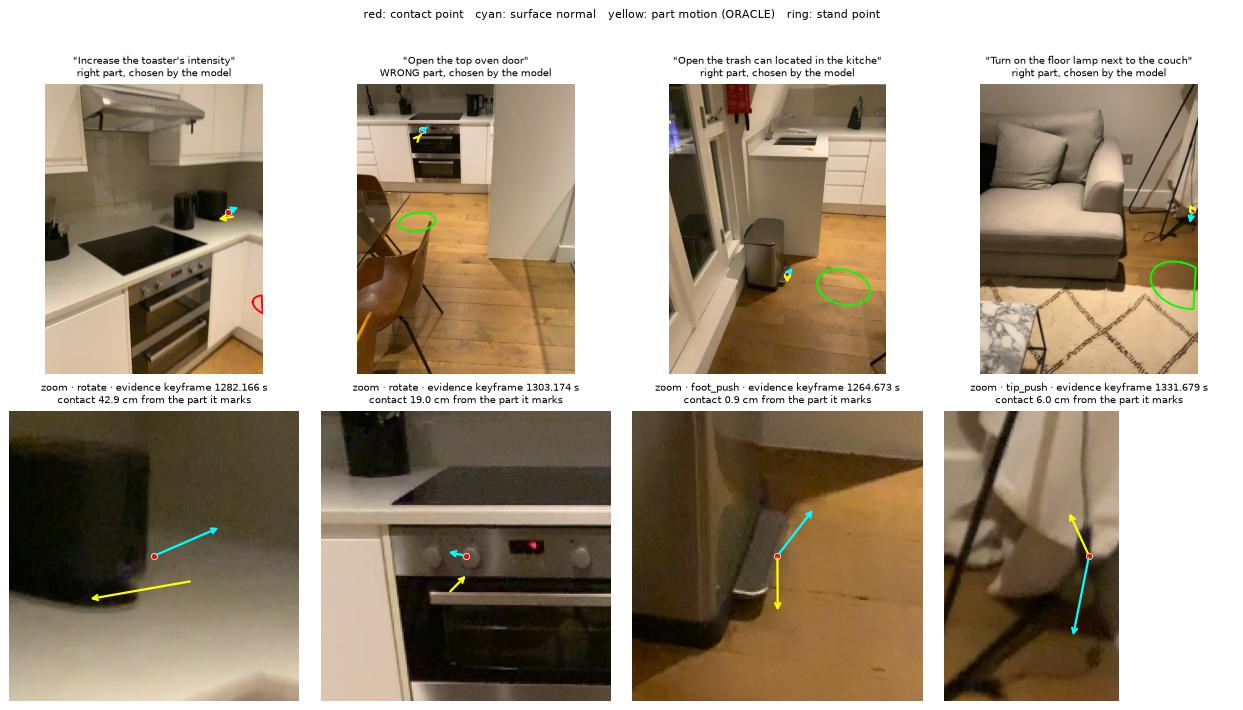

geometry computed at query time in 17 ms per token (median)


In [14]:
view = scan_view(scene)  # ground-truth scan, for scoring and display
by_time = dict(zip(keyframes, frames))
picked, read_ms = [], []
for index in examples:
    top, mark, token, _ = chosen_token[index]
    fallback = token is None
    if fallback:  # no valid answer: the best region among the keyframes that were shown, if any has one
        token = next((int(scores[index].best_token[k]) for k in top if scores[index].best_token[k] != S.NO_TOKEN), None)
    if token is None:
        continue
    start = time.time()
    readout = T.read_geometry(memory, token, frames, scene.up)
    read_ms.append(1000 * (time.time() - start))
    right = int(truth[token]) in tasks[index].parts
    note = ("right part" if right else "WRONG part") + (", search fallback" if fallback else ", chosen by the model")
    picked.append((f'"{tasks[index].text[:40]}"\n{note}', tasks[index].text, H.readout_entry(scene, memory, readout, int(truth[token]))))

H.readout_figure(scene, [title for title, _, _ in picked], [entry for _, _, entry in picked], by_time, view)
plt.show()
print(f"geometry computed at query time in {np.median(read_ms):.0f} ms per token (median)")

## 环节 11、12 · 人形走近并操作
> **这一步做什么：** 用上一步现算的接触点、法向和站立点摆放 SMPL-X 人形：站到站立点，面向部件，部件低就蹲下，把手（踩踏板时是脚）伸到接触点。展示用的画面从整段视频里挑一帧能同时看到人和部件的。
> **状态：** 真实（运动学，没有物理；走路是简单步态）。黄色箭头的部件运动是 ORACLE。

**怎么看图：** 上排贴在真实视频帧上，用输入深度处理遮挡。下排把同一个人放进激光扫描里检查，洋红色是真实部件。视频是同样内容的走近过程。

2 of 4 examples have a video frame that shows both the person and the part


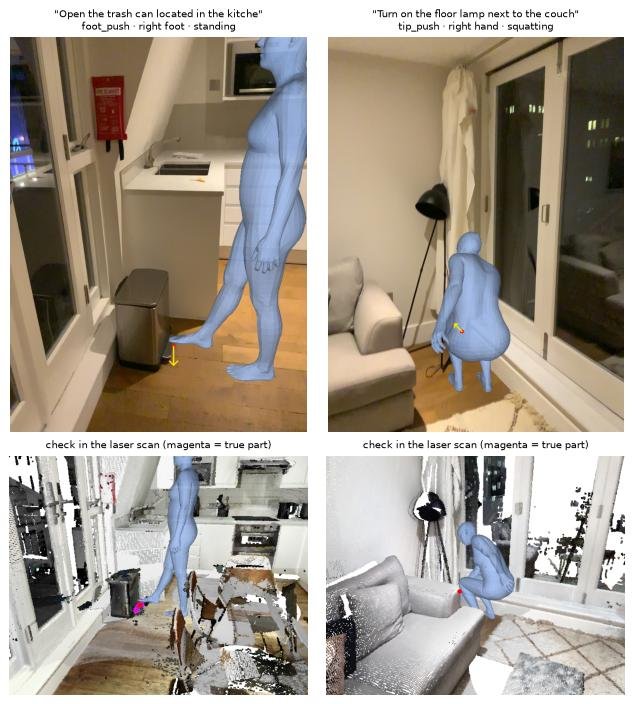

,query,acts with,hand/foot to true part,feet above true floor,body inside scan geometry
0,Open the trash can located in the kitchen near the sink,"right foot, standing",5.1 cm,+5.5 cm,0.0%
1,Turn on the floor lamp next to the couch,"right hand, squatting",9.0 cm,+2.3 cm,0.0%


In [15]:
body = load_smplx(ROOT / "data" / "body_models" / "smplx" / "SMPLX_NEUTRAL.npz")
shots = shots_for(scene, [(text, entry) for _, text, entry in picked], memory.floor, body, MONO_ID, MONO_CACHE)
print(f"{len(shots)} of {len(picked)} examples have a video frame that shows both the person and the part")
humanoid_figure(scene, shots, body, view)
plt.show()
display(shots_table(scene, shots, view))
CLIP = ASSETS / "mem_l2_approach.mp4"
render_approach_video(scene, P.Memory(memory.times, (), memory.floor, np.zeros((0, 3))), body, shots, view, CLIP)
Video(str(CLIP), embed=True, width=960)

---
## 环节 13 · 评测
> **这一步做什么：** 对照激光扫描打分，并记录成本。
> **状态：** 真实，但只有一个场景。

第一张表比较两种记忆读出的几何量。**L2** 一行：每个部件取像素最多的那个 token，读取时现算。**v1** 一行：写入时就按部件编号算好存下的显式条目。两者用的是同一帧的同一种深度，所以接触点误差应当接近；差别来自 L2 不知道部件编号（区域可能把相邻部件连在一起，同一个部件也可能被拆成几个）。第二张表是这次运行的耗时。

In [16]:
l2_entries = H.readout_memory(scene, memory, frames, truth)
display(scoreboard(scene, {"L2: geometry read at query time, no part ids": l2_entries,
                           "v1: explicit entries written with part ids": explicit}, view))
timing = pd.DataFrame([("write the memory (features, tokens, links)", f"{write_seconds:.0f} s once per video"),
                       ("search keyframes", f"{search_ms:.1f} ms per query"),
                       ("vision-language model reads 3 marked keyframes", f"{readings['seconds'].median():.0f} s per query"),
                       ("contact point, normal, stand point", f"{np.median(read_ms):.0f} ms per query")],
                      columns=["step", "time on the CPU"]).set_index("step")
timing

,parts in memory,contact error (median),contact on the part (≤ 3 cm),stand point free in the scan
depth used to build the memory,,,,
"L2: geometry read at query time, no part ids",39 of 38,11.1 cm,13%,74%
v1: explicit entries written with part ids,29 of 38,7.7 cm,14%,93%


,time on the CPU
step,
"write the memory (features, tokens, links)",89 s once per video
search keyframes,0.2 ms per query
vision-language model reads 3 marked keyframes,60 s per query
"contact point, normal, stand point",17 ms per query


## 环节 14、15 · 交互检测、事件与状态时间线
> **状态：** 示意。SceneFun3D 的视频里没有人操作，这两个环节在这段视频上做不了，下面只画出打算怎么做。按第三轮讨论的安排，S1 做完重建对照之后，先用一段 HD-EPIC 视频把它们的最小版本跑通。

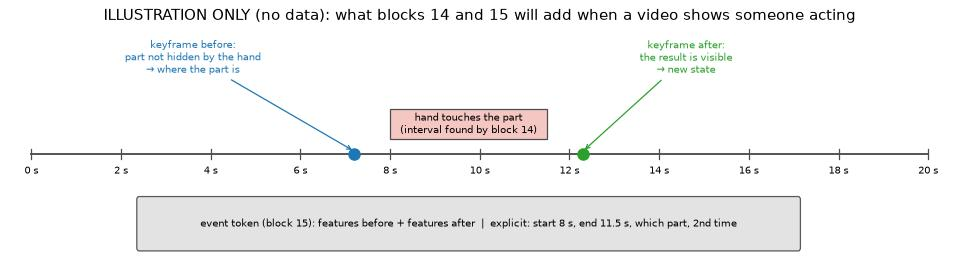

In [17]:
H.events_sketch()
plt.show()

---
## 这次运行的数字汇总

下表由上面各格的结果自动汇总，并保存到 `runs/mem_l2/summary.json`。再强调一次：一个场景、18 个任务，这些数字只说明流程能跑通、误差从哪里来。

In [18]:
recall = {name: S.recall_at(values, (1, 3)) for name, values in hits.items()}
link = H.linking_scores(memory, truth).iloc[0]
summary = {
    "keyframes": len(keyframes), "tokens": len(memory.tokens), "true parts with a token": int(link["true parts with a token"]),
    "parts in the memory": memory.n_parts, "parts linked exactly right": link["parts linked exactly right"],
    "tokens whose part is not mixed": link["tokens whose part is not mixed"],
    "a true part stays in one piece (mean share)": link["a true part stays in one piece (mean share)"],
    "regions that join two true parts": H.mixed_regions(memory, part_labels),
    "same true part seen twice: median distance (cm)": round(H.same_part_gap_cm(memory, frames, truth), 1),
    "parts seen with 10 / 20 / 40 / 80 keyframes": " / ".join(str(v) for v in seen_by_count.values()),
    "camera turn rate of the keyframes with regions, min / median / max (deg/s)": " / ".join(
        f"{value:.0f}" for value in (rates[with_regions].min(), np.median(rates[with_regions]), rates[with_regions].max())),
    "v1 contact error against camera turn rate: rank correlation": round(turn_correlation, 2),
    "answerable tasks": len(tasks),
    "right keyframe in top 1 / top 3, plain semantics": "{:.0%} / {:.0%}".format(*recall["plain semantics (whole keyframes)"].values()),
    "right keyframe in top 1 / top 3, with affordance tokens": "{:.0%} / {:.0%}".format(*recall["both together (used below)"].values()),
    "action type guessed from the words": f"{sum(guessed)} of {len(tasks)}",
    "right part chosen by the vision-language model": f"{int(readings['right part chosen'].sum())} of {len(readings)}",
    "write time (s)": round(write_seconds), "token features (KB)": round(memory.feature_bytes() / 1e3),
}
RUNS.mkdir(parents=True, exist_ok=True)
(RUNS / "summary.json").write_text(json.dumps(summary, indent=1))
pd.DataFrame(summary.items(), columns=["what", "this run"]).set_index("what")

,this run
what,
keyframes,40
tokens,62
true parts with a token,28
parts in the memory,39
parts linked exactly right,14 of 28
tokens whose part is not mixed,94%
a true part stays in one piece (mean share),83%
regions that join two true parts,3
same true part seen twice: median distance (cm),25.7


**请你看的几个点**（意见写在 [pipeline.ipynb](pipeline.ipynb) 对应环节的格子里）

1. **环节 4：** 现在的 affordance map 是标注投影加填充。相邻的同类部件会连成一个区域，这在模型预测的图上同样会出现。是否需要让它同时输出"部件之间的分界"。
2. **环节 6：** 关联现在主要靠位置。同一个部件两次看到的位置差经常超过相邻部件的间距。可以改进的方向：用同一帧里部件之间的相对位置；或者只在检索到之后、在候选关键帧之间做关联。
3. **环节 10：** 找关键帧这一步，affordance token 是否按你设想的方式起作用；动作类型应该怎么进入检索。
4. **环节 10：** 视觉语言模型现在看的是整幅关键帧加编号框，小部件在图里很小。是否改成给它每个候选区域的放大图。
5. **环节 7、8：** 几何量读取时现算、不存，是否符合你对"隐式"的设想。
6. **画面：** 这些图里哪些适合对外展示，哪些需要换一种画法。